# Pontos de mudança: em que ano cada mudança acontece

Os cadernos anteriores comparam **períodos legais** (antes de 1831, 1831–1850, 1850–1871, 1871–1888). Este caderno pergunta outra coisa:
**em que ano** a medida muda de patamar, olhando a série **ano a ano**, e se esse ano cai perto de uma data legal (1831, 1850, 1871).
Vale para as 5 medidas de proporção: recompensa, nação citada e marcas no corpo (nas fugas), % de anúncios que são fuga e % feminino nos aluguéis.

**Como se estima.** Supomos **um só degrau**: antes do ano *k* a proporção é uma, depois é outra. Testamos cada ano como *k* e ficamos com o de maior
verossimilhança binomial.
- **IC do ano:** sorteamos os anúncios com reposição (2.000 vezes, semente fixa) e repetimos a busca; o intervalo é onde caem 95% dos anos achados.
- **p:** teste de permutação (2.000 embaralhamentos dos anos entre os anúncios); mede se o ganho de verossimilhança do melhor degrau é maior que o de um degrau achado em dados sem relação com o ano.
- **Sem ponto definido:** se o IC cobre mais de 8 anos ou p >= 0,05.
- **Anos com menos de 20 anúncios** aparecem na série (círculo aberto) mas **não entram no ajuste**.
- **Três visões:** *bruta* (todos os anúncios), *só JC* (sem os bibs `094170_01` e `706744`) e *ajustada* (anúncios ponderados para igualar a mistura de tipos entre os períodos; as contagens usam o n efetivo).

Corpus `corp3`, campos `c6`, temas `t5`. Os números dos comentários foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** (1) o modelo de **um degrau** força uma mudança brusca: se a mudança é gradual, o ano achado é só o ponto médio e o IC tende a ser largo;
> (2) os anúncios vêm de **frases de busca**, não de sorteio, e a cobertura dos jornais varia por ano (veja o caderno `equilibrio_periodos`): uma mudança de jornal pode parecer mudança no tempo;
> (3) os anúncios de um ano não são independentes (reanúncios, mesmo dono), então **os IC são um pouco otimistas**; (4) as medidas 4 (idade) e 7 a 9 (temas) não são proporções e ficam de fora.

## Preparação: ler o corpus e calcular os pontos

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from hdb import config
from hdb.banco import BancoSupabase
from hdb.medidas import carregar
from hdb.pontos_mudanca import DATAS_LEGAIS, MEDIDAS, MIN_N_ANO, SEM_PONTO, calcular_pontos, texto_ponto
from hdb.relatorio import num, tabela

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
df = carregar(BancoSupabase(), config)
print(f"{len(df)} anúncios no corpus {config.VERSAO_CORPUS} com período legal")
if len(df) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")
PONTOS = calcular_pontos(df)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2191 anúncios no corpus corp3 com período legal


## 1. Tabela dos pontos
Ano = primeiro ano do novo patamar, com o IC de 95% entre colchetes. **Datas legais cobertas** = quais entre 1831, 1850 e 1871 cabem dentro do IC (visão bruta).
`antes → depois` = proporção (%) antes e depois do melhor ponto, na visão bruta (mesmo quando ele não se define).

In [2]:
def celula(p):
    if not p["definido"]:   # mostra a melhor estimativa e por que não se define
        melhor = f"; melhor estimativa {p['ano']} [{p['baixo']}–{p['alto']}]" if p["ano"] else ""
        return f"{SEM_PONTO} ({p['motivo'] or 'n insuficiente'}{melhor})"
    return texto_ponto(p, com_ic=True)

linhas = []
for i, nome in MEDIDAS.items():
    r = PONTOS[i]
    b = r["bruta"]
    linhas.append((i, nome, celula(b), celula(r["jc"]), celula(r["ajustada"]),
                   "–" if b["p"] != b["p"] else ("<0,001" if b["p"] < 0.001 else num(b["p"], 3)),
                   ", ".join(map(str, b["cobre"])) if b["definido"] and b["cobre"] else "nenhuma",
                   f"{num(b['antes'] * 100, 1)} → {num(b['depois'] * 100, 1)}" if b["ano"] else "–",
                   len(b["anos_fora"])))
display(Markdown(tabela(("#", "Medida", "Ano (bruta) [IC]", "Ano (só JC)", "Ano (ajustada)", "p (bruta)",
                         "Datas legais cobertas", "antes → depois", "Nº de anos com n < 20 (fora do ajuste)"), linhas)))

| # | Medida | Ano (bruta) [IC] | Ano (só JC) | Ano (ajustada) | p (bruta) | Datas legais cobertas | antes → depois | Nº de anos com n < 20 (fora do ajuste) |
|---|---|---|---|---|---|---|---|---|
| 1 | Recompensa nas fugas | sem ponto definido (IC cobre 10 anos (> 8); melhor estimativa 1853 [1851–1860]) | sem ponto definido (IC cobre 10 anos (> 8); melhor estimativa 1853 [1851–1860]) | sem ponto definido (IC cobre 10 anos (> 8); melhor estimativa 1853 [1851–1860]) | 0,002 | nenhuma | 57,1 → 26,1 | 47 |
| 2 | Nação citada nas fugas | sem ponto definido (IC cobre 9 anos (> 8); melhor estimativa 1860 [1852–1860]) | sem ponto definido (IC cobre 9 anos (> 8); melhor estimativa 1860 [1852–1860]) | sem ponto definido (IC cobre 9 anos (> 8); melhor estimativa 1860 [1852–1860]) | 0,038 | nenhuma | 36,9 → 10,0 | 47 |
| 3 | Marcas no corpo nas fugas | sem ponto definido (p = 0,975 >= 0,05; melhor estimativa 1860 [1851–1860]) | sem ponto definido (p = 0,975 >= 0,05; melhor estimativa 1860 [1851–1860]) | sem ponto definido (p = 0,975 >= 0,05; melhor estimativa 1860 [1851–1860]) | 0,975 | nenhuma | 11,7 → 15,0 | 47 |
| 5 | Parcela feminina nos aluguéis | sem ponto definido (IC cobre 27 anos (> 8); melhor estimativa 1860 [1848–1874]) | sem ponto definido (IC cobre 27 anos (> 8); melhor estimativa 1860 [1848–1874]) | sem ponto definido (p = 0,058 >= 0,05; melhor estimativa 1860 [1848–1874]) | 0,048 | nenhuma | 58,1 → 69,8 | 33 |
| 6 | Anúncios que são fuga | sem ponto definido (IC cobre 12 anos (> 8); melhor estimativa 1829 [1825–1836]) | sem ponto definido (IC cobre 18 anos (> 8); melhor estimativa 1880 [1863–1880]) | sem ponto definido (IC cobre 57 anos (> 8); melhor estimativa 1824 [1824–1880]) | <0,001 | nenhuma | 69,1 → 17,0 | 20 |

**O que mostra:** com a regra combinada antes de ver o resultado (um degrau; ponto "definido" só se p < 0,05 **e** o intervalo cobrir no máximo 8 anos), **nenhuma das 5 medidas tem ponto definido, em nenhuma das três visões**. Mas há três tipos de resultado:

- **Recompensa nas fugas:** melhor degrau em **1853** (intervalo 1851 a 1860; p = 0,002). O intervalo cobre 10 anos, por isso é "impreciso", mas **não inclui 1831, 1850 nem 1871**: a queda da recompensa parece se concentrar **depois da Lei Eusébio de Queirós e bem antes do Ventre Livre**, e não nas datas das leis.
- **Nação citada:** melhor degrau em 1860 (1852 a 1860; p = 0,038), com o mesmo tipo de leitura; o ano 1860 é o último com anúncios suficientes antes da queda, então é um **efeito de borda** possível.
- **Parcela feminina dos aluguéis** (1860, intervalo 1848 a 1874, p = 0,048) e **marcas no corpo** (p = 0,975): sem ponto. As marcas caem de uma vez entre antes de 1831 e 1831–1850, antes da região onde há anos com anúncios suficientes.
- **% de anúncios que são fuga:** 1829 na visão bruta e **1880 só com o JC**: o degrau muda de lugar conforme o jornal, o que confirma o efeito do Diário do Rio no primeiro período.

## 2. Séries anuais e ponto de mudança
Pontos = proporção do ano com intervalo de Wilson (visão bruta); **círculo aberto** = ano com menos de 20 anúncios, fora do ajuste.
**Linha cheia** = ponto de mudança (visão bruta) e **faixa** = seu IC de 95%; **linha pontilhada verde** = ponto só JC;
**tracejadas cinza** = datas legais (1831, 1850, 1871). Se não há ponto definido, não há linha cheia nem faixa.

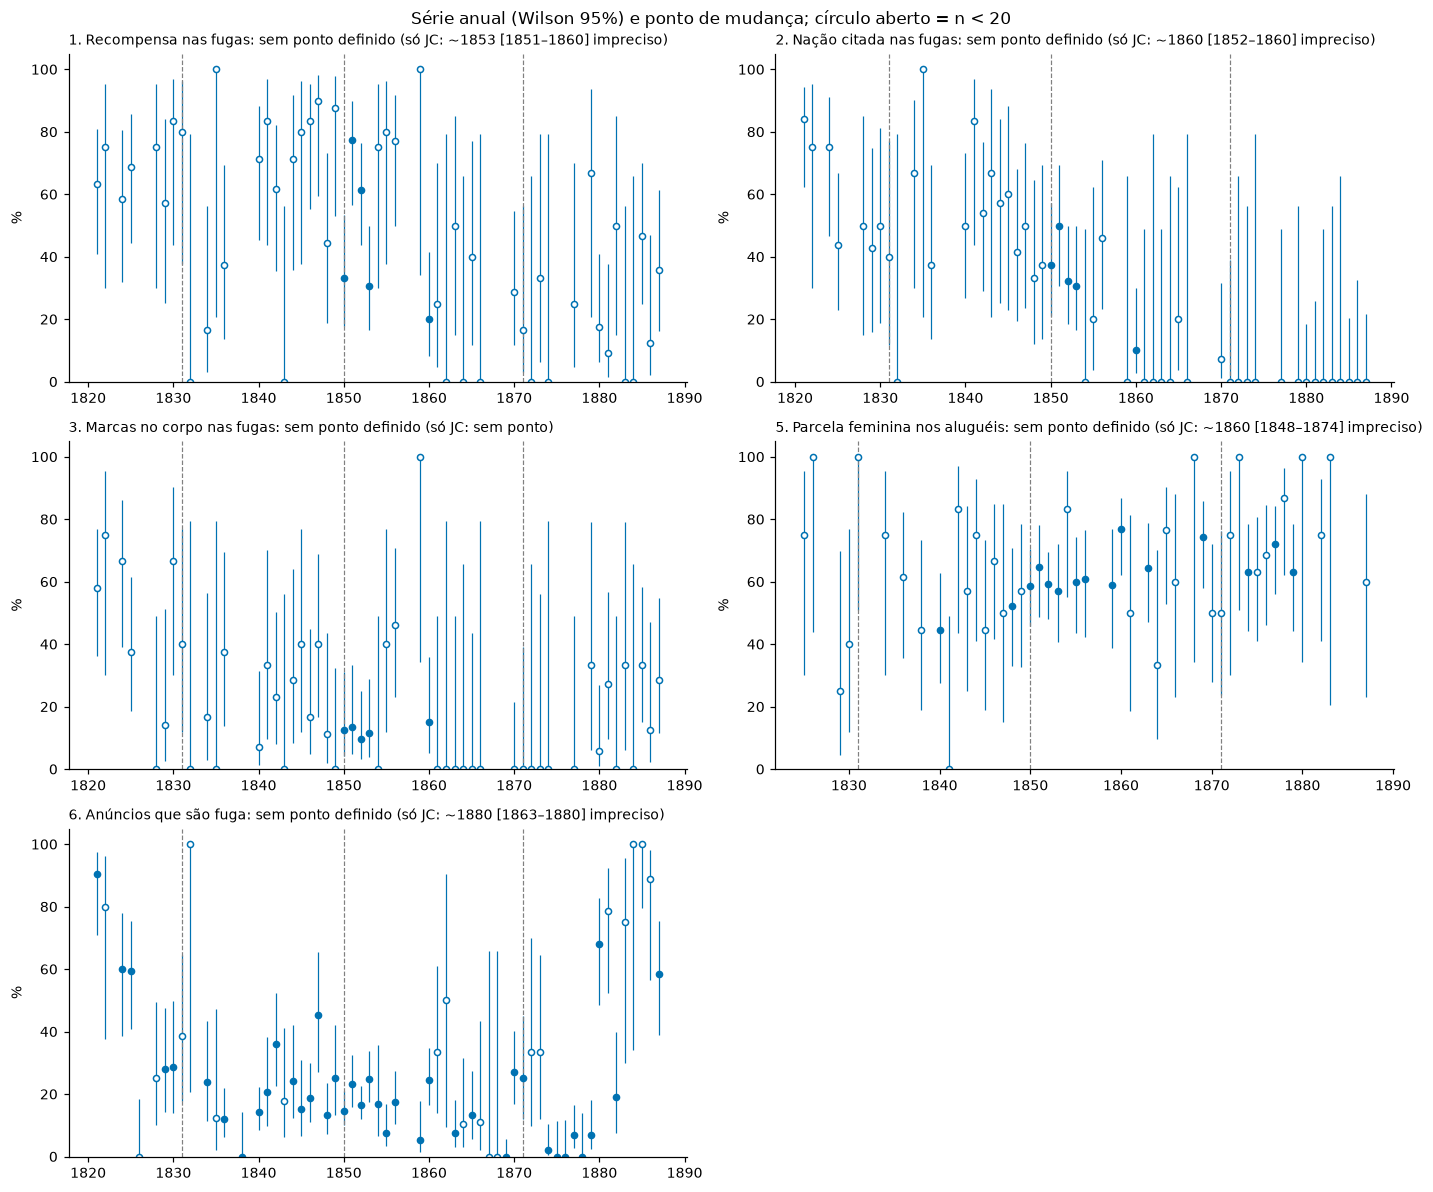

In [3]:
fig, eixos = plt.subplots(3, 2, figsize=(13, 11))
for ax, (i, nome) in zip(eixos.ravel(), MEDIDAS.items()):
    r = PONTOS[i]
    s = r["serie"]["bruta"]
    y = s["p"] * 100
    yerr = np.array([np.maximum(y - s["baixo"] * 100, 0), np.maximum(s["alto"] * 100 - y, 0)])
    for ok, mfc in ((True, "#0072B2"), (False, "white")):
        m = (s["ok"] == ok).to_numpy()
        ax.errorbar(s["ano"][m], y[m], yerr=yerr[:, m], fmt="o", ms=4, color="#0072B2", mfc=mfc, lw=0.8, capsize=0)
    for d in DATAS_LEGAIS:
        ax.axvline(d, color="gray", ls="--", lw=0.8)
    b, j = r["bruta"], r["jc"]
    if b["definido"]:
        ax.axvspan(b["baixo"], b["alto"] + 1, color="#D55E00", alpha=0.15)
        ax.axvline(b["ano"], color="#D55E00", lw=1.5)
    if j["definido"]:
        ax.axvline(j["ano"], color="#009E73", ls=":", lw=1.5)
    ax.set_title(f"{i}. {nome}: " + (f"{texto_ponto(b, com_ic=True)} (só JC: {texto_ponto(j)})" if b["definido"] else f"{SEM_PONTO} (só JC: {texto_ponto(j)})"),
                 fontsize=9, loc="left")
    ax.set_ylabel("%")
    ax.set_ylim(bottom=0)
eixos.ravel()[-1].axis("off")
fig.suptitle("Série anual (Wilson 95%) e ponto de mudança; círculo aberto = n < 20")
fig.tight_layout(); plt.show()

**O que mostra (séries anuais):** a amostra **não é uniforme no tempo**. Os anos de 1850 a 1853 têm mais de 100 fugas cada, e vários anos (1857, 1858, 1862, 1867, 1868 e os de 1883 a 1886) têm quase nenhuma. Anos com menos de 20 anúncios (círculo aberto) **ficam fora do ajuste**, então o ponto só pode cair onde há anos suficientes dos dois lados. Por isso os intervalos são largos e várias estimativas caem em 1860, o último ano bem coberto antes de uma lacuna.

## 3. Quanto cada ano pesa
Número de anúncios por ano em cada medida (visão bruta): onde a série é rala, o ponto estimado é frágil.

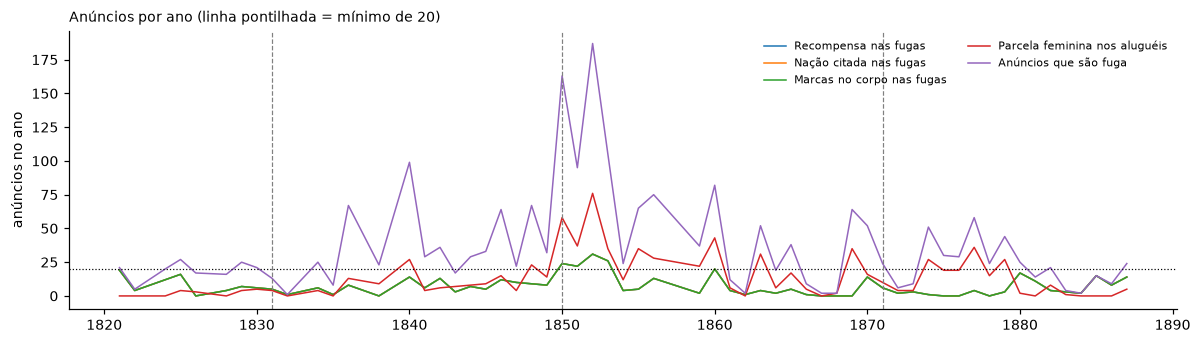

In [4]:
tab = pd.DataFrame({MEDIDAS[i]: PONTOS[i]["serie"]["bruta"].set_index("ano")["n"] for i in MEDIDAS}).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 3.2))
for col in tab.columns:
    ax.plot(tab.index, tab[col], lw=1, label=col)
ax.axhline(MIN_N_ANO, color="black", ls=":", lw=0.8)
for d in DATAS_LEGAIS:
    ax.axvline(d, color="gray", ls="--", lw=0.8)
ax.set_ylabel("anúncios no ano"); ax.legend(fontsize=7, frameon=False, ncol=2)
ax.set_title("Anúncios por ano (linha pontilhada = mínimo de 20)", fontsize=9, loc="left")
fig.tight_layout(); plt.show()

**O que isso autoriza dizer:**

1. A recompensa cai **depois de 1850**, em um ponto que **não coincide com nenhuma data de lei** (1831, 1850, 1871); o ano exato é impreciso (1851 a 1860).
2. **Não dá para datar** a queda das marcas, da nação nem a alta da parcela feminina com esta amostra.
3. A queda da parcela de fugas entre os anúncios **depende do jornal** (1829 contra 1880): é mistura da amostra.

**Limites:** o mínimo de 20 anúncios por ano é alto para este corpus; com 10, alguns pontos poderiam sair definidos, mas eu não mudei a regra depois de ver o resultado. Um único degrau descreve mal mudanças graduais (recompensa e nação são graduais no quadro). A coleta por células de busca, não por anos, deixa lacunas que **só mais coleta resolve**. Na visão ajustada, a medida de % de fuga é quase degenerada (a padronização iguala a mistura de tipos).